In [8]:
import pandas as pd
import numpy as np

# ============================================================================
# 1. LOAD CLEANED DATA & PRE-PROCESS NEW TABLES
# ============================================================================
base_path = '..\\ACL_9th-F1\\F1_clean\\'

results = pd.read_csv('..\\ACL_9th-F1\\F1_clean\\results_clean_with_rank.csv')
races = pd.read_csv(base_path + 'races_clean.csv')
driver_standings = pd.read_csv(base_path + 'driver_standings_clean.csv')
qualifying = pd.read_csv('..\\ACL_9th-F1\\F1\\' + 'qualifying.csv')
drivers = pd.read_csv(base_path + 'drivers_clean.csv')
circuits = pd.read_csv(base_path + 'circuits_clean.csv')
constructors = pd.read_csv(base_path + 'constructors_clean.csv')
results['podium'] = (results['positionOrder'] <= 3).astype(int)

# Load the new tables
lap_times = pd.read_csv('..\\ACL_9th-F1\\F1\\lap_times.csv')
pit_stops = pd.read_csv('..\\ACL_9th-F1\\F1\\pit_stops.csv')
constructor_standings = pd.read_csv('..\\ACL_9th-F1\\F1\\constructor_standings.csv')

# Pre-process 'rank' (fastest lap rank) to numeric, converting '\N' to NaN
if 'rank' in results.columns:
    results['rank'] = pd.to_numeric(results['rank'].replace(r'\N', np.nan), errors='coerce')

# Aggregate average lap position per driver per race
race_lap_avg = lap_times.groupby(['raceId', 'driverId'])['position'].mean().reset_index(name='race_avg_lap_pos')

# Aggregate average pit stop duration per driver per race
pit_avg = pit_stops.groupby(['raceId', 'driverId'])['milliseconds'].mean().reset_index(name='race_avg_pit_ms')

# =============================================================================
# 2. DRIVER FORM FEATURES (Carries over between seasons)
# =============================================================================
# Merge results with races (including circuitId for track record) and new aggregates
driver_form = results[['raceId', 'driverId', 'positionOrder', 'podium', 'rank']].copy()
driver_form = driver_form.merge(races[['raceId', 'race_year', 'race_round', 'circuitId']], on='raceId')
driver_form = driver_form.merge(race_lap_avg, on=['raceId', 'driverId'], how='left')
driver_form = driver_form.merge(pit_avg, on=['raceId', 'driverId'], how='left')

# Sort chronologically by driver
driver_form = driver_form.sort_values(by=['driverId', 'race_year', 'race_round'])

# --- RECENT FORM (Shifted to exclude current race) ---
driver_form['driver_prev_position'] = driver_form.groupby('driverId')['positionOrder'].shift(1)
driver_form['driver_prev_podium'] = driver_form.groupby('driverId')['podium'].shift(1).fillna(0)

g = driver_form.groupby('driverId')   # every calculation below stays inside one driver's own races
gc_circuit = driver_form.groupby(['driverId', 'circuitId']) # For track affinity

# Rolling 5-Race Averages (shift(1) = only earlier races)
driver_form['driver_avg_pos_last_5'] = g['positionOrder'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
driver_form['driver_avg_lap_pos_last_5'] = g['race_avg_lap_pos'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
driver_form['driver_avg_pit_ms_last_5'] = g['race_avg_pit_ms'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
driver_form['driver_avg_speed_rank_last_5'] = g['rank'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# --- CAREER TOTALS (all earlier races of this driver) ---
driver_form['driver_career_avg_pos'] = g['positionOrder'].transform(lambda s: s.shift(1).expanding().mean())
driver_form['driver_career_podiums'] = g['podium'].transform(lambda s: s.shift(1).cumsum()).fillna(0)

# [NEW] Driver Experience (Total career races prior to this one)
driver_form['driver_career_races'] = g.cumcount()

# [NEW] Circuit Affinity (Historical average finish at this specific track)
driver_form['driver_avg_pos_at_circuit'] = gc_circuit['positionOrder'].transform(lambda s: s.shift(1).expanding().mean())


# Isolate columns for final merge (Drops circuitId here so it doesn't duplicate in Step 4)
driver_features_to_keep = [
    'raceId', 'driverId', 'driver_prev_position', 'driver_prev_podium', 
    'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_pit_ms_last_5', 
    'driver_avg_speed_rank_last_5', 'driver_career_avg_pos', 'driver_career_podiums',
    'driver_career_races', 'driver_avg_pos_at_circuit'
]
driver_form = driver_form[driver_features_to_keep]

# =============================================================================
# 3. DRIVER STANDINGS FEATURES (Resets to 0 every season)
# =============================================================================
ds = driver_standings.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')
ds = ds.sort_values(by=['driverId', 'race_year', 'race_round'])

ds['pre_race_points'] = ds.groupby(['driverId', 'race_year'])['driver_points_cumm'].shift(1).fillna(0)
ds['pre_race_wins'] = ds.groupby(['driverId', 'race_year'])['driver_wins_cumm'].shift(1).fillna(0)
ds['won_previous_race'] = ds.groupby(['driverId', 'race_year'])['pre_race_wins'].diff().fillna(0)

ds = ds[['raceId', 'driverId', 'pre_race_points', 'pre_race_wins', 'won_previous_race']]

# =============================================================================
# 3.5 CONSTRUCTOR FORM & STANDINGS (NEW)
# =============================================================================
# --- CONSTRUCTOR FORM ---
constructor_form = results[['raceId', 'constructorId', 'positionOrder', 'podium']].copy()
constructor_form = constructor_form.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')

# Best finish and total podiums for the team per race
constructor_form = constructor_form.groupby(['raceId', 'constructorId', 'race_year', 'race_round']).agg({
    'positionOrder': 'min',
    'podium': 'sum'
}).reset_index()

constructor_form = constructor_form.sort_values(by=['constructorId', 'race_year', 'race_round'])
gc = constructor_form.groupby('constructorId')   # every calculation stays inside one team's own races

constructor_form['constructor_prev_pos'] = gc['positionOrder'].shift(1)
constructor_form['constructor_avg_pos_last_5'] = gc['positionOrder'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
constructor_form['constructor_career_podiums'] = gc['podium'].transform(lambda s: s.shift(1).cumsum()).fillna(0)

constructor_form = constructor_form[['raceId', 'constructorId', 'constructor_prev_pos', 'constructor_avg_pos_last_5', 'constructor_career_podiums']]

# --- CONSTRUCTOR STANDINGS ---
cs = constructor_standings.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')
cs = cs.sort_values(by=['constructorId', 'race_year', 'race_round'])

# Adjust column names 'constructor_points_cumm'/'constructor_wins_cumm' if they differ in your CSV
cs['pre_race_constructor_points'] = cs.groupby(['constructorId', 'race_year'])['points'].shift(1).fillna(0)
cs['pre_race_constructor_wins'] = cs.groupby(['constructorId', 'race_year'])['wins'].shift(1).fillna(0)

cs = cs[['raceId', 'constructorId', 'pre_race_constructor_points', 'pre_race_constructor_wins']]

# =============================================================================
# 4. BUILD THE BASE TRAINING TABLE (Strict Leakage Control)
# =============================================================================
final_df = results[['raceId', 'driverId', 'constructorId', 'grid', 'podium']].copy()

final_df = final_df.merge(races[['raceId', 'race_year', 'race_round', 'circuitId']], on='raceId', how='left')

final_df = final_df.merge(qualifying[['raceId', 'driverId', 'position']], on=['raceId', 'driverId'], how='left')
final_df.rename(columns={'position': 'quali_position'}, inplace=True)

final_df = final_df.merge(drivers[['driverId', 'drivers_nationality']], on='driverId', how='left')
final_df.rename(columns={'drivers_nationality': 'driver_nationality'}, inplace=True)

final_df = final_df.merge(circuits[['circuitId', 'country']], on='circuitId', how='left')
final_df.rename(columns={'country': 'circuit_country'}, inplace=True)

final_df = final_df.merge(constructors[['constructorId', 'name']], on='constructorId', how='left')
final_df.rename(columns={'name': 'constructor_name'}, inplace=True)

final_df = final_df.merge(driver_form, on=['raceId', 'driverId'], how='left')
final_df = final_df.merge(ds, on=['raceId', 'driverId'], how='left')

# Add Constructor details
final_df = final_df.merge(constructor_form, on=['raceId', 'constructorId'], how='left')
final_df = final_df.merge(cs, on=['raceId', 'constructorId'], how='left')

# =============================================================================
# 5. HOME RACE FEATURE ENGINEERING
# =============================================================================
# Dictionary mapping F1 nationalities to circuit countries
nationality_to_country = {
    'British': 'UK', 'German': 'Germany', 'Spanish': 'Spain', 'Finnish': 'Finland',
    'Japanese': 'Japan', 'French': 'France', 'Polish': 'Poland', 'Brazilian': 'Brazil',
    'Italian': 'Italy', 'Australian': 'Australia', 'Austrian': 'Austria', 'American': 'USA',
    'Dutch': 'Netherlands', 'Colombian': 'Colombia', 'Portuguese': 'Portugal', 
    'Canadian': 'Canada', 'Indian': 'India', 'Hungarian': 'Hungary', 'Irish': 'Ireland',
    'Danish': 'Denmark', 'Argentine': 'Argentina', 'Belgian': 'Belgium', 
    'South African': 'South Africa', 'Swiss': 'Switzerland', 'Swedish': 'Sweden',
    'Mexican': 'Mexico', 'Russian': 'Russia', 'Chinese': 'China', 
    'Monegasque': 'Monaco', 'New Zealander': 'New Zealand'
}

final_df['driver_home_country'] = final_df['driver_nationality'].map(nationality_to_country).fillna(final_df['driver_nationality'])
final_df['is_home_race'] = (final_df['driver_home_country'] == final_df['circuit_country']).astype(int)
final_df = final_df.drop(columns=['driver_home_country'])

# =============================================================================
# 6. FINAL CLEANUP & EXPORT
# =============================================================================
# 6A. Grid position with grid 0 (pit-lane start / no grid slot) moved behind the last car of THAT race,
#     then use it to fill missing qualifying positions
last_slot = final_df.groupby('raceId')['grid'].transform('max')
final_df['grid_pos'] = final_df['grid'].where(final_df['grid'] != 0, last_slot + 1)
final_df['quali_position'] = final_df['quali_position'].fillna(final_df['grid_pos'])

# --- [NEW] QUALIFYING AND GRID FEATURES ---
# 6A-1. Teammate Head-to-Head (1 if driver qualified <= teammate)
teammate_best_quali = final_df.groupby(['raceId', 'constructorId'])['quali_position'].transform('min')
final_df['outqualified_teammate'] = (final_df['quali_position'] <= teammate_best_quali).astype(int)

# 6A-2. Grid Penalty Delta (Positive number means they took a grid penalty drop)
final_df['grid_penalty_delta'] = final_df['grid_pos'] - final_df['quali_position']

# 6B. Fill zero-baselines for debuts
final_df['pre_race_points'] = final_df['pre_race_points'].fillna(0)
final_df['pre_race_wins'] = final_df['pre_race_wins'].fillna(0)
final_df['won_previous_race'] = final_df['won_previous_race'].fillna(0)
final_df['driver_prev_podium'] = final_df['driver_prev_podium'].fillna(0)
final_df['pre_race_constructor_points'] = final_df['pre_race_constructor_points'].fillna(0)
final_df['pre_race_constructor_wins'] = final_df['pre_race_constructor_wins'].fillna(0)

# 6C. Fill rookie/debut Form with "back of pack" baseline (20)
final_df['driver_prev_position'] = final_df['driver_prev_position'].fillna(20)
final_df['driver_avg_pos_last_5'] = final_df['driver_avg_pos_last_5'].fillna(20)
final_df['driver_career_avg_pos'] = final_df['driver_career_avg_pos'].fillna(20)
final_df['constructor_prev_pos'] = final_df['constructor_prev_pos'].fillna(20)
final_df['constructor_avg_pos_last_5'] = final_df['constructor_avg_pos_last_5'].fillna(20)
final_df['driver_avg_pos_at_circuit'] = final_df['driver_avg_pos_at_circuit'].fillna(20) # [NEW] Track debut baseline

# 6D. Fill missing lap/pit stop data (due to decades of missing coverage)
final_df['driver_avg_speed_rank_last_5'] = final_df['driver_avg_speed_rank_last_5'].fillna(20)
final_df['driver_avg_lap_pos_last_5'] = final_df['driver_avg_lap_pos_last_5'].fillna(20)
# Fill missing pit stop milliseconds with a heavy penalty (e.g. 40000ms / 40s)
final_df['driver_avg_pit_ms_last_5'] = final_df['driver_avg_pit_ms_last_5'].fillna(40000)

# 6E. Championship points relative to the leader BEFORE this race (same 0-1 scale in every season)
leader = final_df.groupby('raceId')['pre_race_points'].transform('max')
final_df['points_share'] = np.where(leader > 0, final_df['pre_race_points'] / leader, 0)    # round 1: nobody has points -> 0

leader_c = final_df.groupby('raceId')['pre_race_constructor_points'].transform('max')
final_df['constructor_points_share'] = np.where(leader_c > 0, final_df['pre_race_constructor_points'] / leader_c, 0)

final_df.to_csv(base_path + 'FINAL_training_table2.csv', index=False)
print(f"Final Training Table built successfully! Shape: {final_df.shape}")
print("Columns:", final_df.columns.tolist())

Final Training Table built successfully! Shape: (26668, 36)
Columns: ['raceId', 'driverId', 'constructorId', 'grid', 'podium', 'race_year', 'race_round', 'circuitId', 'quali_position', 'driver_nationality', 'circuit_country', 'constructor_name', 'driver_prev_position', 'driver_prev_podium', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_pit_ms_last_5', 'driver_avg_speed_rank_last_5', 'driver_career_avg_pos', 'driver_career_podiums', 'driver_career_races', 'driver_avg_pos_at_circuit', 'pre_race_points', 'pre_race_wins', 'won_previous_race', 'constructor_prev_pos', 'constructor_avg_pos_last_5', 'constructor_career_podiums', 'pre_race_constructor_points', 'pre_race_constructor_wins', 'is_home_race', 'grid_pos', 'outqualified_teammate', 'grid_penalty_delta', 'points_share', 'constructor_points_share']


### We are going to discard the years before 2004 due to the absence of qualifying systems in these years

In [ ]:
final_df = final_df[final_df['race_year'] > 2003]

In [ ]:
final_df.isnull().sum()

--- Correlation Matrix (X features vs Y target) ---
podium                          1.000000
points_share                    0.463541
constructor_points_share        0.410479
pre_race_wins                   0.370284
pre_race_constructor_wins       0.367341
driver_prev_podium              0.350418
pre_race_points                 0.317099
pre_race_constructor_points     0.291754
driver_career_podiums           0.267819
won_previous_race               0.254660
constructor_career_podiums      0.239666
driver_career_races             0.162264
outqualified_teammate           0.089311
driver_avg_pit_ms_last_5        0.015275
grid_penalty_delta              0.005482
is_home_race                   -0.019443
driver_avg_speed_rank_last_5   -0.165290
driver_avg_lap_pos_last_5      -0.203190
driver_avg_pos_at_circuit      -0.225061
driver_prev_position           -0.273774
constructor_prev_pos           -0.288678
driver_career_avg_pos          -0.289176
constructor_avg_pos_last_5     -0.330723
drive

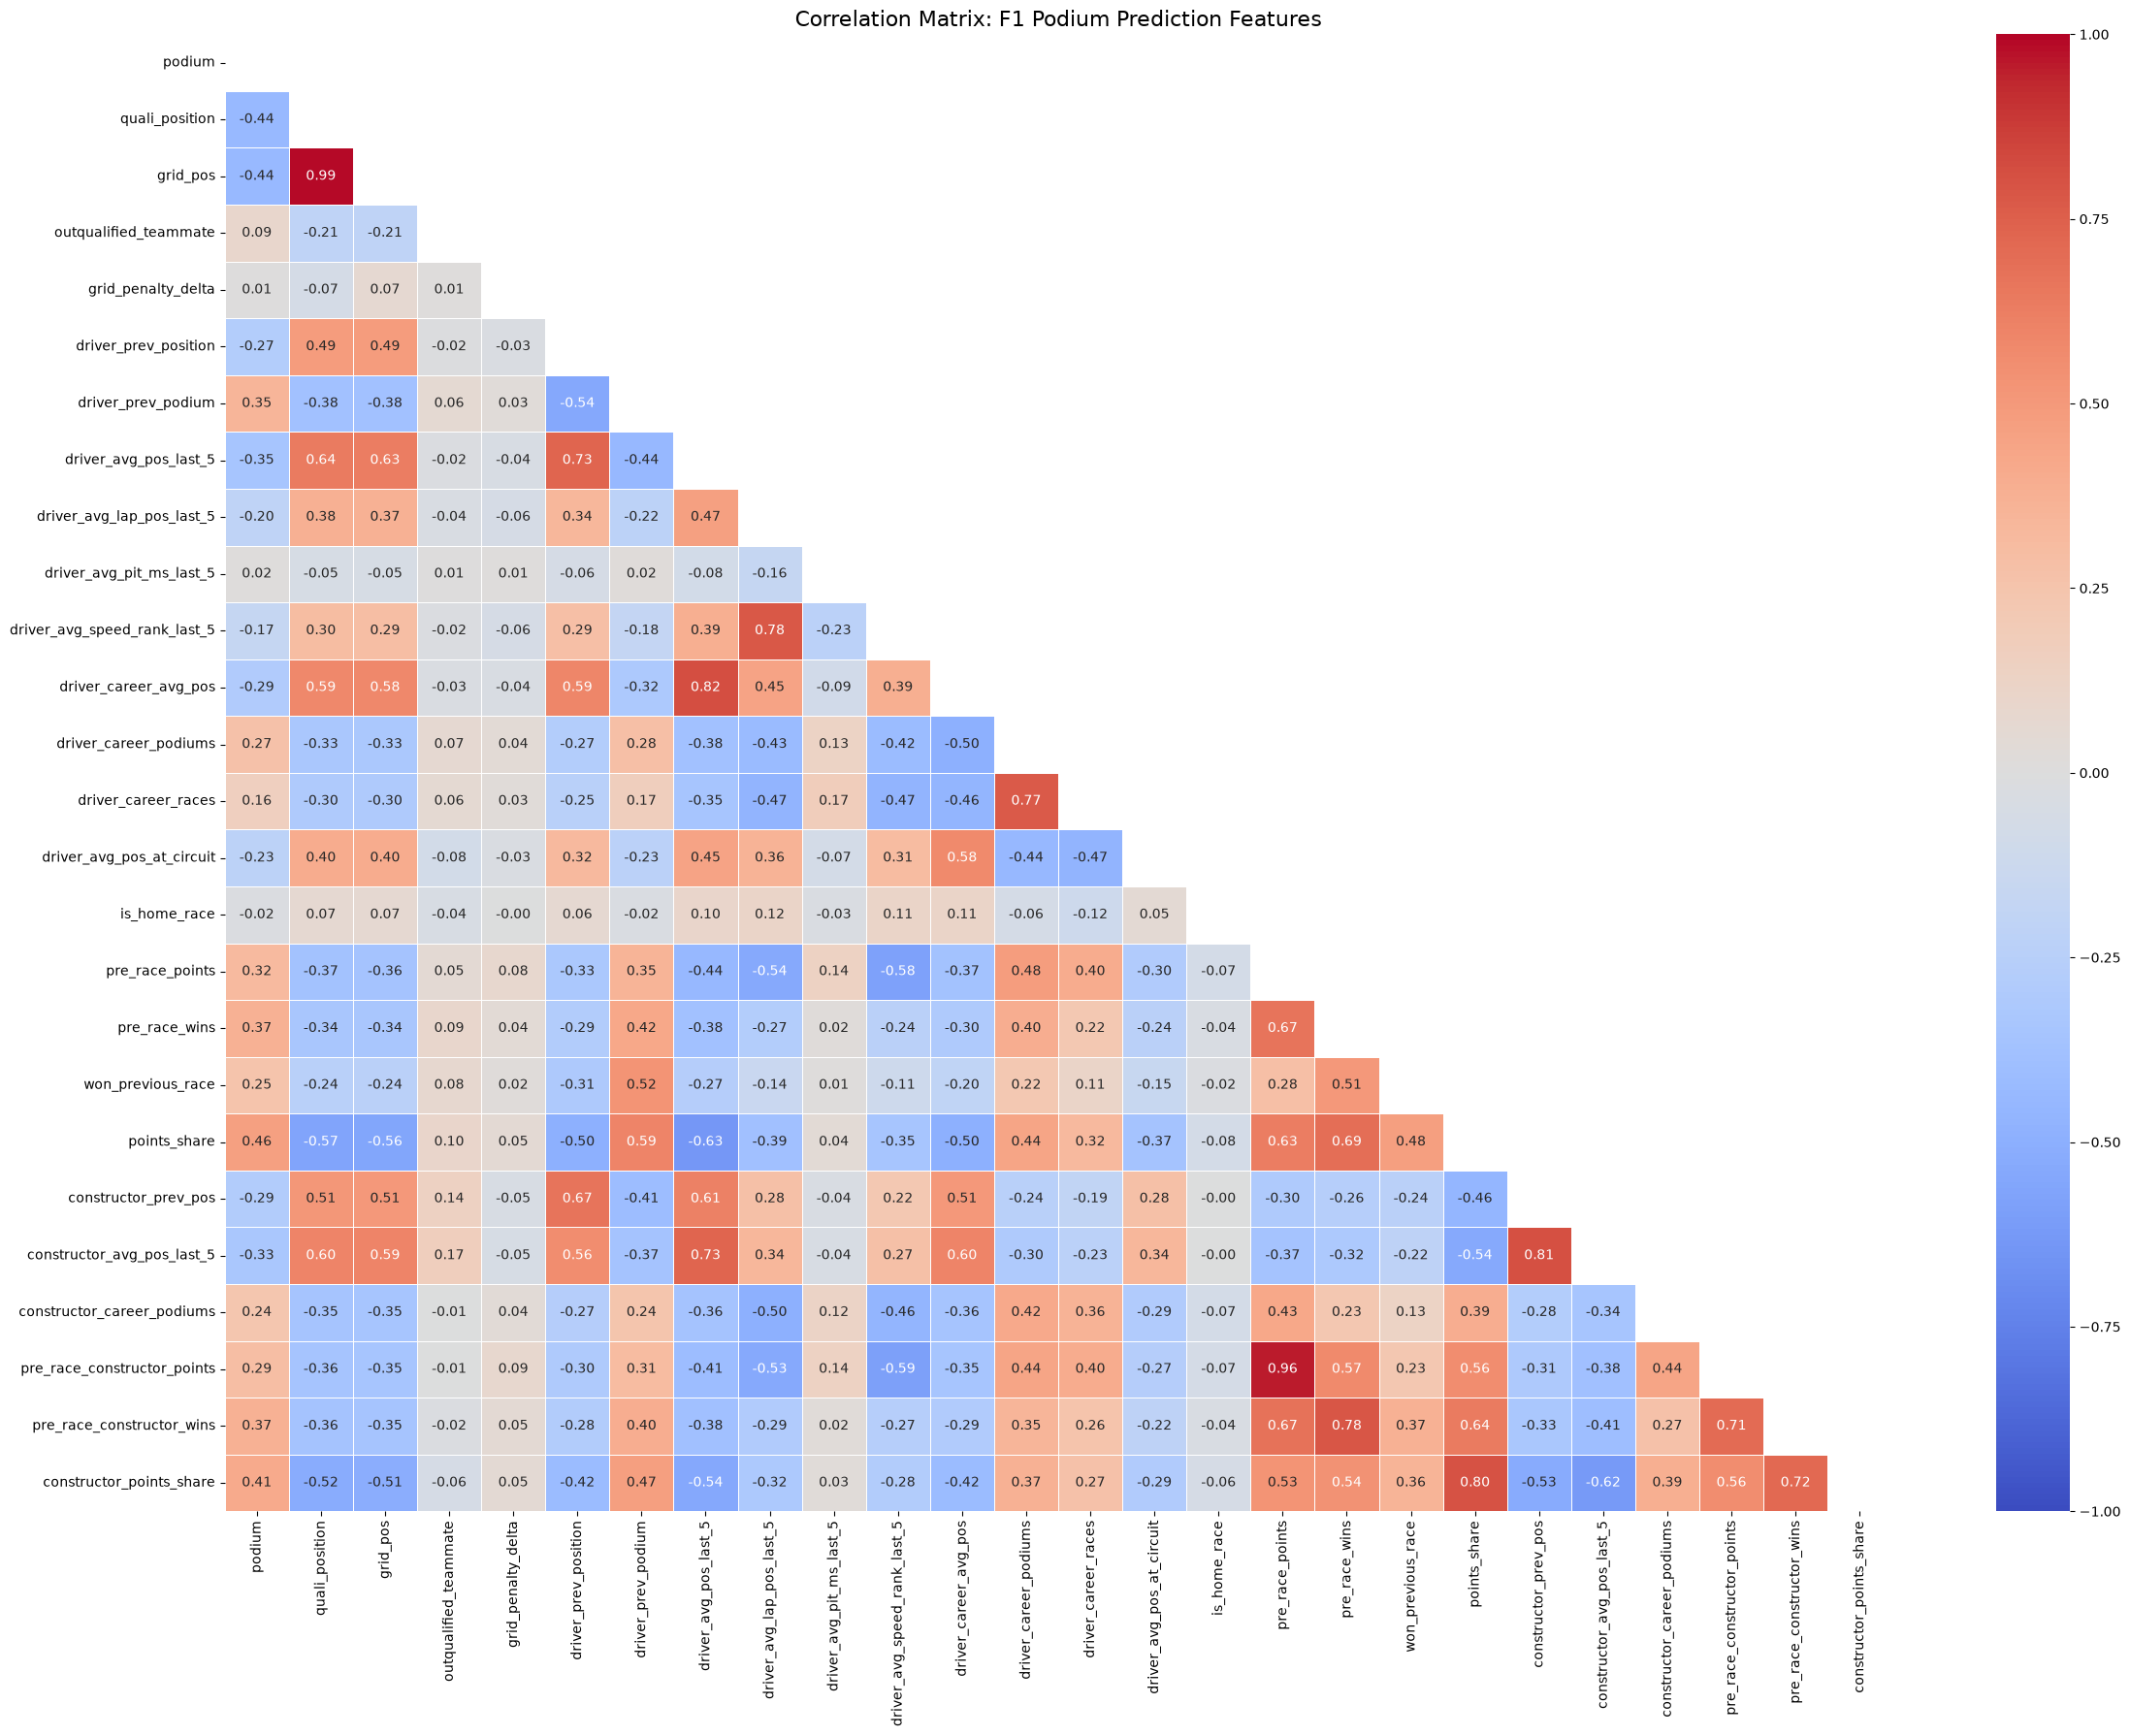

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define all numeric features and the target variable
selected_columns = [
    # --- Target ---
    "podium",
    
    # --- Grid & Qualifying ---
    "quali_position", 
    "grid_pos", 
    "outqualified_teammate", 
    "grid_penalty_delta",
    
    # --- Driver Recent Form ---
    "driver_prev_position", 
    "driver_prev_podium",
    "driver_avg_pos_last_5", 
    "driver_avg_lap_pos_last_5", 
    "driver_avg_pit_ms_last_5", 
    "driver_avg_speed_rank_last_5",
    
    # --- Driver Career & Momentum ---
    "driver_career_avg_pos", 
    "driver_career_podiums", 
    "driver_career_races", 
    "driver_avg_pos_at_circuit",
    "is_home_race",
    
    # --- Driver Championship Standings ---
    "pre_race_points", 
    "pre_race_wins",
    "won_previous_race", 
    "points_share", 
    
    # --- Constructor (Car) Form & Standings ---
    "constructor_prev_pos",
    "constructor_avg_pos_last_5", 
    "constructor_career_podiums", 
    "pre_race_constructor_points",
    "pre_race_constructor_wins", 
    "constructor_points_share"
]

# 2. Calculate the correlation matrix
matrix = final_df[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
# Print sorted correlations specifically against the 'podium' target
print(matrix['podium'].sort_values(ascending=False))

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(24, 18))
# Using a mask to hide the upper triangle makes large heatmaps much easier to read
import numpy as np
mask = np.triu(np.ones_like(matrix, dtype=bool))

sns.heatmap(matrix, mask=mask, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix: F1 Podium Prediction Features", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
final_df['race_year'].value_counts().sort_index().plot(kind='bar', figsize=(16, 4))
plt.title('Number of races per season')
plt.xlabel('season'); plt.ylabel('races')
plt.show()
print('first season:', final_df['race_year'].min(), '| last season:', final_df['race_year'].max(),
      '| seasons:', final_df['race_year'].nunique())

## Feature Selection

### 1. Reason for the chosen features (with evidence)
Every candidate must be **known before the race starts** (after qualifying). The evidence is the correlation with
`podium` on the modelling seasons (2004+, 8,650 rows, from the heatmap above) and the podium-rate plots below.

| Group | Feature | r with podium | Why it is relevant | Decision |
|---|---|---|---|---|
| Starting position | `quali_position` | −0.50 | Pace on the same weekend | Keep |
| | `grid` | −0.48 | Actual starting slot (after penalties) | Keep |
| Driver recent form | `driver_avg_lap_pos_last_5` | −0.48 | Average running position in the last 5 races | Keep |
| | `driver_avg_pos_last_5` | −0.47 | Average finish in the last 5 races | Keep |
| | `driver_avg_speed_rank_last_5` | −0.45 | Fastest-lap rank in the last 5 races (raw pace) | Keep |
| | `driver_prev_podium` | +0.41 | Podium in the previous race | Keep |
| | `driver_prev_position` | −0.35 | Finish in the previous race | Keep |
| | `won_previous_race` | +0.30 | Won the previous race | Keep |
| Driver career | `driver_career_avg_pos` | −0.38 | Long-term level of the driver | Keep |
| | `driver_career_podiums` | +0.29 | Proven podium history | Keep |
| Driver standings | `pre_race_points` | +0.43 | Season performance so far | Keep |
| | `pre_race_wins` | +0.43 | Season wins so far | Keep |
| Team form | `constructor_avg_pos_last_5` | −0.46 | Car strength over the last 5 races | Keep |
| | `constructor_prev_pos` | −0.40 | Team's best finish in the previous race | Keep |
| | `constructor_career_podiums` | +0.24 | Team's long-term history | Keep |
| Team standings | `pre_race_constructor_wins` | +0.45 | Team wins this season | Keep |
| | `pre_race_constructor_points` | +0.41 | Team points this season | Keep |
| Weak | `driver_avg_pit_ms_last_5` | +0.01 | Average pit-stop time in the last 5 races | **Drop** |
| | `is_home_race` | +0.00 | Racing in the driver's home country | **Drop** (kept for Q2 only) |

**Why the two features are dropped**
- `driver_avg_pit_ms_last_5`: pit-stop data only exists from 2011, so **all 2004–2010 rows (32% of the table)**
  hold the fill value 40,000 ms instead of a real time. On real values the relationship is weak and not one-directional
  (podium rate 21% → 10% → 16% from shortest to longest stops), and the linear correlation is +0.01.
- `is_home_race`: only 3.9% of rows are home races, and their podium rate is the same as everyone else's
  (14.7% vs 14.3%), which matches our answer to Q2.

**Redundancy (correlation between features ≥ 0.8)**: `pre_race_points` ~ `pre_race_constructor_points` (0.96),
`grid` ~ `quali_position` (0.93), `driver_avg_pos_last_5` ~ `driver_avg_lap_pos_last_5` (0.91). They are kept because
they still differ in meaningful cases (e.g. grid penalties: grid ≠ qualifying for a share of drivers; a driver can be
much better or worse than his team-mate). Tree models handle this overlap; we do not interpret logistic-regression
coefficients one by one.

### 2. Plotting the effect of the features
For each feature, the rows are split into 10 equal-size groups (deciles) from the lowest to the highest value, and
we plot the share of podiums in each group. A useful feature shows bars clearly above and below the red line
(overall podium rate, 14.3%).

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define all numeric features and the target variable
selected_columns = [
    # --- Target ---
    "podium",
    
    # --- Grid & Qualifying ---
    "quali_position", 
    "grid_pos", 
    "outqualified_teammate", 
    "grid_penalty_delta",
    
    # --- Driver Recent Form ---
    "driver_prev_position", 
    "driver_prev_podium",
    "driver_avg_pos_last_5", 
    "driver_avg_lap_pos_last_5", 
    "driver_avg_pit_ms_last_5", 
    "driver_avg_speed_rank_last_5",
    
    # --- Driver Career & Momentum ---
    "driver_career_avg_pos", 
    "driver_career_podiums", 
    "driver_career_races", 
    "driver_avg_pos_at_circuit",
    "is_home_race",
    
    # --- Driver Championship Standings ---
    "pre_race_points", 
    "pre_race_wins",
    "won_previous_race", 
    "points_share", 
    
    # --- Constructor (Car) Form & Standings ---
    "constructor_prev_pos",
    "constructor_avg_pos_last_5", 
    "constructor_career_podiums", 
    "pre_race_constructor_points",
    "pre_race_constructor_wins", 
    "constructor_points_share"
]

# 2. Calculate the correlation matrix
matrix = final_df[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
# Print sorted correlations specifically against the 'podium' target
print(matrix['podium'].sort_values(ascending=False))

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(24, 18))
# Using a mask to hide the upper triangle makes large heatmaps much easier to read
import numpy as np
mask = np.triu(np.ones_like(matrix, dtype=bool))

sns.heatmap(matrix, mask=mask, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix: F1 Podium Prediction Features", fontsize=16)
plt.tight_layout()
plt.show()

KeyError: "['grid_pos'] not in index"

**Observations**
- **Starting position is decisive:** the best decile of `grid` / `quali_position` reaches a ~65% podium rate, and from
  the 4th decile on it is almost 0.
- **Recent form behaves the same way:** the best decile of `driver_avg_pos_last_5`, `driver_avg_lap_pos_last_5`,
  `driver_avg_speed_rank_last_5` and `constructor_avg_pos_last_5` is at 55–60%, the worst near 0.
- **Yes/no features split clearly:** a podium in the previous race → ~50% podium rate (vs ~8%); winning the previous
  race → ~63% (vs ~12%).
- **Standings rise steadily:** the highest groups of `pre_race_points` / `pre_race_constructor_points` reach ~50%.
- **`driver_prev_position` rises slightly again at the worst values:** a retirement in the previous race gives a high
  position number even to fast drivers, so one bad race is a noisy signal — the 5-race average is cleaner.
- **`constructor_career_podiums` is not one-directional** (the 6th group is far above the 7th): a long history counts
  old successful teams that are no longer fast, so the recent team-form features carry the stronger signal.
- **`driver_avg_pit_ms_last_5` and `is_home_race` stay around the red line** → dropped (see the table above).

### 3. Leakage-safe form features (only past races)
The prediction is made after qualifying and before the race, so **no information from the race itself** may enter a
feature.

- **Excluded from features:** everything produced by the race being predicted (`positionOrder`, points, laps, status,
  that race's fastest-lap rank, lap times and pit stops).
- **Form and career features:** within each driver (or team), sorted by `race_year` and `race_round`, every value is
  computed from `shift(1)`, i.e. only from earlier races:
  `groupby('driverId')[col].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())`.
  The shift, the rolling window and the running totals all stay **inside the group**. An earlier version applied
  `.rolling()` / `.expanding()` after the grouping had ended, so the windows ran across drivers. This made
  `driver_career_podiums` correlate *negatively* with podium (−0.09); after the fix it is +0.29.
- **Standings features:** the cumulative points and wins are shifted by one race within the same driver/team and
  season, so they are the standings **before** the race (0 before the first race of a season).
- **Same-weekend information:** only `grid` and `quali_position`, both fixed before the start.
- **The season filter (2004+) is applied after the features are built**, so earlier seasons still count as history.

**Check:** for 200 random rows, the last-5 average finish and the career podium count are recomputed by hand from
strictly earlier races only, and compared with the table.

In [ ]:
# Leakage check: recompute two form features by hand for random rows, using ONLY races that happened earlier
hist = results[['raceId', 'driverId', 'positionOrder', 'podium']].merge(races[['raceId', 'race_year', 'race_round']], on='raceId')
hist['order'] = hist['race_year'] * 100 + hist['race_round']                  # time order: season, then round

sample = final_df.sample(200, random_state=42)
checks = []
for _, row in sample.iterrows():
    now = row['race_year'] * 100 + row['race_round']
    past = hist[(hist['driverId'] == row['driverId']) & (hist['order'] < now)].sort_values('order')   # strictly earlier races
    exp_avg5 = past['positionOrder'].tail(5).mean() if len(past) else 20       # 20 = notebook's fill for debuts
    exp_career = past['podium'].sum()
    checks.append({'avg_pos_last_5 matches': np.isclose(row['driver_avg_pos_last_5'], exp_avg5),
                   'career_podiums matches': row['driver_career_podiums'] == exp_career})
checks = pd.DataFrame(checks)
print('rows checked:', len(checks))
print(checks.mean().rename('share matching'))

**Result:** 200 / 200 rows match for both features (share = 1.0). Every value is computed only from races before the
one being predicted, so the form features are leakage-safe.

## Model training
### Train / validation / test split
The data is split **by season**, in time order: the models learn from past seasons and are judged on later ones,
exactly how they would be used for real (predicting the next races). A random split would put races of the same
season in train and test, letting the model "see the future".
- **Train 2004–2019:** all seasons with complete data up to the validation period.
- **Validation 2020–2021:** used to choose hyperparameters and the probability threshold.
- **Test 2022–2024:** touched only once, at the end, for the final scores.
Whole seasons stay together, so no race is split across sets.

In [ ]:
MODEL_FEATURES = ["quali_position", "grid_pos", "driver_avg_pos_last_5", "driver_avg_lap_pos_last_5",
                  "driver_avg_speed_rank_last_5", "driver_prev_position", "driver_prev_podium",
                  "driver_career_avg_pos", "driver_career_podiums", "points_share", "pre_race_wins",
                  "won_previous_race", "constructor_prev_pos", "constructor_avg_pos_last_5",
                  "constructor_career_podiums", "constructor_points_share", "pre_race_constructor_wins"]

# Split by SEASON (time order): learn from the past, predict the future
train_df = final_df[final_df['race_year'] <= 2019]
val_df   = final_df[final_df['race_year'].between(2020, 2021)]
test_df  = final_df[final_df['race_year'] >= 2022]

X_train, y_train = train_df[MODEL_FEATURES], train_df['podium']
X_val,   y_val   = val_df[MODEL_FEATURES],   val_df['podium']
X_test,  y_test  = test_df[MODEL_FEATURES],  test_df['podium']

split_summary = pd.DataFrame({
    'seasons': [f"{d['race_year'].min()}-{d['race_year'].max()}" for d in (train_df, val_df, test_df)],
    'races':   [d['raceId'].nunique() for d in (train_df, val_df, test_df)],
    'rows':    [len(d) for d in (train_df, val_df, test_df)],
    'podium rate': [round(d['podium'].mean(), 3) for d in (train_df, val_df, test_df)]},
    index=['train', 'validation', 'test'])
split_summary

### Shared evaluation tools
- **Metrics:** ROC-AUC and PR-AUC judge how well the model *ranks* podium finishers above the rest (PR-AUC is the main
  one because podiums are rare, ~15%). F1, precision and recall need a yes/no decision, so they depend on a threshold.
- **Threshold:** the probability cut-off that gives the best F1 **on validation**; never chosen on test.

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve

def best_threshold(y, prob):
    # the probability cut-off that gives the highest F1 -- chosen on VALIDATION only
    precision, recall, thresholds = precision_recall_curve(y, prob)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thresholds[np.argmax(f1[:-1])]

def scores(y, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y, prob), 'PR-AUC': average_precision_score(y, prob),
            'F1': f1_score(y, pred), 'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred)}

results = []          # one row per model, filled as we go
def record(name, prob_train, prob_val, threshold):
    row = {'model': name, 'threshold': round(float(threshold), 3)}
    row.update({f'train {k}': v for k, v in scores(y_train, prob_train, threshold).items()})
    row.update({f'val {k}': v for k, v in scores(y_val, prob_val, threshold).items()})
    results.append(row)
    return pd.DataFrame(results).set_index('model')[['threshold', 'train ROC-AUC', 'train PR-AUC', 'train F1',
                                                     'val ROC-AUC', 'val PR-AUC', 'val F1']].round(3)

### Baseline: "starting in the top 3 means a podium"
Every model must beat this simple rule; otherwise the extra features and the model add nothing.

In [ ]:
# Baseline rule: "a driver starting in the top 3 finishes on the podium"
# score = 1 / grid_pos (higher = better start); cut-off 1/3 means grid_pos <= 3
rule_train = 1 / train_df['grid_pos']
rule_val   = 1 / val_df['grid_pos']
record('Baseline: grid <= 3', rule_train, rule_val, threshold=1/3)

### Model 1: Logistic regression
A linear model: it adds up the features with weights and turns the sum into a probability. Simple and hard to
overfit, so it is a strong first model. Features are standardised (scaler fit on train only). The regularisation
strength `C` is chosen on validation PR-AUC.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Try a few regularisation strengths (C); choose the one with the best VALIDATION PR-AUC
lr_search = []
for C in [0.01, 0.1, 1, 10]:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))   # scaler is fit on TRAIN only
    m.fit(X_train, y_train)
    lr_search.append({'C': C, 'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
lr_search = pd.DataFrame(lr_search)
print(lr_search.round(4).to_string(index=False))
best_C = lr_search.loc[lr_search['val PR-AUC'].idxmax(), 'C']
print('chosen C =', best_C)

lr_model = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=3000)).fit(X_train, y_train)
p_train_lr, p_val_lr = lr_model.predict_proba(X_train)[:, 1], lr_model.predict_proba(X_val)[:, 1]
record('Logistic regression', p_train_lr, p_val_lr, best_threshold(y_val, p_val_lr))

### Model 2: Random forest
Many decision trees, each trained on a random sample of the rows and features; the forest averages their votes.
Trees do not need scaled features. `min_samples_leaf` (the smallest group of rows a leaf may hold) controls how
detailed the trees get: too small and they memorise the training data. It is chosen on validation PR-AUC.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Random forest (Lab 4): many decision trees, each trained on a random sample of rows/features; their votes are averaged.
# Trees do not need scaled features, so the unscaled X is used.
# min_samples_leaf controls how detailed each tree may get (small = can memorise training rows = overfitting)
rf_search = []
for leaf in [1, 5, 20, 50]:
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rf_search.append({'min_samples_leaf': leaf,
                      'train PR-AUC': average_precision_score(y_train, m.predict_proba(X_train)[:, 1]),
                      'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
rf_search = pd.DataFrame(rf_search)
print(rf_search.round(4).to_string(index=False))
best_leaf = int(rf_search.loc[rf_search['val PR-AUC'].idxmax(), 'min_samples_leaf'])
print('chosen min_samples_leaf =', best_leaf)

rf_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=best_leaf, random_state=42, n_jobs=-1).fit(X_train, y_train)
p_train_rf = rf_model.predict_proba(X_train)[:, 1]
p_val_rf   = rf_model.predict_proba(X_val)[:, 1]
thr_rf = best_threshold(y_val, p_val_rf)
record('Random forest', p_train_rf, p_val_rf, thr_rf)

### Model 3: Gradient boosting
Trees are built one after another, each correcting the mistakes of the previous ones. It overfits quickly on this
data, so it uses a small learning rate, a minimum of 100 rows per leaf and L2 regularisation; tree size and number of
trees are chosen on validation PR-AUC.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Gradient boosting: trees are built one after another, each one correcting the mistakes of the previous ones.
# max_leaf_nodes = how complex each tree is; max_iter = how many trees; min_samples_leaf = smallest group a leaf may hold.
# Small learning rate + regularisation, because boosting overfits this data quickly (train score rises, val score falls).
gb_search = []
for leaves in [3, 7, 15]:
    for n_trees in [100, 200, 400]:
        m = HistGradientBoostingClassifier(learning_rate=0.03, max_leaf_nodes=leaves, max_iter=n_trees,
                                           min_samples_leaf=100, l2_regularization=1.0, random_state=42).fit(X_train, y_train)
        gb_search.append({'max_leaf_nodes': leaves, 'trees': n_trees,
                          'train PR-AUC': average_precision_score(y_train, m.predict_proba(X_train)[:, 1]),
                          'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
gb_search = pd.DataFrame(gb_search)
print(gb_search.round(4).to_string(index=False))
best_gb = gb_search.loc[gb_search['val PR-AUC'].idxmax()]
gb_params = dict(learning_rate=0.03, max_leaf_nodes=int(best_gb['max_leaf_nodes']), max_iter=int(best_gb['trees']),
                 min_samples_leaf=100, l2_regularization=1.0, random_state=42)
print('chosen:', gb_params)

gb_model = HistGradientBoostingClassifier(**gb_params).fit(X_train, y_train)
p_train_gb = gb_model.predict_proba(X_train)[:, 1]
p_val_gb   = gb_model.predict_proba(X_val)[:, 1]
thr_gb = best_threshold(y_val, p_val_gb)
record('Gradient boosting', p_train_gb, p_val_gb, thr_gb)

## Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

# Accuracy = share of ALL rows (podium and no podium) predicted correctly, using each model's validation threshold.
# Test probabilities are only scored here -- nothing is chosen from them.
thr_lr = best_threshold(y_val, p_val_lr)          # the old LR cell did not save its threshold
acc_models = {
    'Always "no podium" (reference)': (np.zeros(len(y_train)), np.zeros(len(y_val)), np.zeros(len(y_test)), 0.5),
    'Baseline: grid <= 3':            (1 / train_df['grid_pos'], 1 / val_df['grid_pos'], 1 / test_df['grid_pos'], 1/3),
    'Logistic regression':            (p_train_lr, p_val_lr, lr_model.predict_proba(X_test)[:, 1], thr_lr),
    'Random forest':                  (p_train_rf, p_val_rf, rf_model.predict_proba(X_test)[:, 1], thr_rf),
    'Gradient boosting':              (p_train_gb, p_val_gb, gb_model.predict_proba(X_test)[:, 1], thr_gb),
}
acc_rows = []
for name, (p_tr, p_va, p_te, thr) in acc_models.items():
    acc_rows.append({'model': name,
                     'train accuracy': accuracy_score(y_train, (np.asarray(p_tr) >= thr).astype(int)),
                     'val accuracy':   accuracy_score(y_val,   (np.asarray(p_va) >= thr).astype(int)),
                     'test accuracy':  accuracy_score(y_test,  (np.asarray(p_te) >= thr).astype(int))})
pd.DataFrame(acc_rows).set_index('model').round(3)

**Accuracy is not used to choose models.** 85% of rows are non-podiums, so predicting "no podium" for everyone is
already 85% accurate. All models reach ~91%, barely above the grid rule, while PR-AUC (which focuses on the podium
class) separates them clearly: 0.64 for the rule vs 0.73–0.75 for the models.

## Final evaluation on the test set (2022–2024)
Every model is scored once on the unseen test seasons, using the hyperparameters and threshold it received from
validation. Nothing is chosen or changed based on these numbers.

In [ ]:
# FINAL TEST: every model, scored once on the unseen 2022-2024 seasons.
# Nothing is chosen here: each model keeps the settings and threshold it got from validation.
thr_lr = best_threshold(y_val, p_val_lr)          # same threshold the old LR cell used (it didn't save it)

test_probs = {
    'Baseline: grid <= 3': (1 / test_df['grid_pos'],                  1/3),
    'Logistic regression': (lr_model.predict_proba(X_test)[:, 1],      thr_lr),   # pipeline scales X_test itself
    'Random forest':       (rf_model.predict_proba(X_test)[:, 1],      thr_rf),
    'Gradient boosting':   (gb_model.predict_proba(X_test)[:, 1],      thr_gb),
}
# when the neural network exists, add:  'Neural network': (nn_model.predict(X_test_nn, verbose=0).ravel(), thr_nn)

final_table = []
for name, (prob, thr) in test_probs.items():
    row = next(r for r in results if r['model'] == name).copy()          # train + validation scores from before
    row.update({f'test {k}': v for k, v in scores(y_test, prob, thr).items()})
    final_table.append(row)
final_table = pd.DataFrame(final_table).set_index('model')
final_table[['threshold', 'train PR-AUC', 'val PR-AUC', 'test PR-AUC', 'train ROC-AUC', 'val ROC-AUC', 'test ROC-AUC',
             'train F1', 'val F1', 'test F1']].round(3)

### Model 4: Neural network (Keras)
A shallow fully connected network (Lab 3): inputs → 1–2 hidden layers with ReLU → one sigmoid output giving the
podium probability. Loss: binary cross-entropy (binary task); optimiser: Adam. Inputs are standardised (scaler fit on
train only). Early stopping watches the validation loss and keeps the best weights, so the network stops before it
starts memorising the training seasons. Two architectures are compared on validation PR-AUC.

In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # hide TensorFlow's info messages
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

# Neural networks need scaled inputs (Lab 3): learn mean/std on TRAIN only
nn_scaler = StandardScaler().fit(X_train)
X_train_nn, X_val_nn, X_test_nn = nn_scaler.transform(X_train), nn_scaler.transform(X_val), nn_scaler.transform(X_test)

def build_model(hidden_units, dropout):
    keras.utils.set_random_seed(42)                       # same starting weights every run -> reproducible
    model = keras.Sequential([layers.Input(shape=(X_train_nn.shape[1],))])
    for units in hidden_units:                            # 1-2 hidden layers = shallow, as the brief asks
        model.add(layers.Dense(units, activation='relu'))
        if dropout > 0:
            model.add(layers.Dropout(dropout))            # randomly switches neurons off while training -> less overfitting
    model.add(layers.Dense(1, activation='sigmoid'))      # one output: probability of a podium (binary task)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')])
    return model

# Early stopping (Lab 3): stop when the validation loss has not improved for 15 epochs, keep the best weights
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

# Two architectures, chosen on validation PR-AUC
nn_search, histories, nn_models = [], {}, {}
for name, units, dropout in [('NN-1: 16 units', [16], 0.0), ('NN-2: 32-16 units + dropout', [32, 16], 0.2)]:
    model = build_model(units, dropout)
    hist = model.fit(X_train_nn, y_train, validation_data=(X_val_nn, y_val),
                     epochs=200, batch_size=64, callbacks=[early_stop], verbose=0)
    histories[name], nn_models[name] = hist, model
    nn_search.append({'network': name, 'epochs run': len(hist.history['loss']),
                      'train PR-AUC': average_precision_score(y_train, model.predict(X_train_nn, verbose=0).ravel()),
                      'val PR-AUC': average_precision_score(y_val, model.predict(X_val_nn, verbose=0).ravel())})
nn_search = pd.DataFrame(nn_search)
print(nn_search.round(4).to_string(index=False))
best_nn = nn_search.loc[nn_search['val PR-AUC'].idxmax(), 'network']
print('chosen:', best_nn)

nn_model = nn_models[best_nn]
p_train_nn = nn_model.predict(X_train_nn, verbose=0).ravel()
p_val_nn   = nn_model.predict(X_val_nn, verbose=0).ravel()
thr_nn = best_threshold(y_val, p_val_nn)
record('Neural network', p_train_nn, p_val_nn, thr_nn)

In [ ]:
import sys; print(sys.version)

In [ ]:
# Training curves (Lab 3): loss on train vs validation for each network
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, hist) in zip(axes, histories.items()):
    ax.plot(hist.history['loss'], label='train loss')
    ax.plot(hist.history['val_loss'], label='validation loss')
    ax.axvline(np.argmin(hist.history['val_loss']), color='grey', linestyle='--', label='best epoch (weights kept)')
    ax.set_title(name); ax.set_xlabel('epoch'); ax.set_ylabel('binary cross-entropy'); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
    'Neural network':      (nn_model.predict(X_test_nn, verbose=0).ravel(), thr_nn),